In [112]:
# Import Python packages
import sys
import os
import subprocess
import matplotlib.pyplot as plt
import numpy as np
import scipy.constants as const

# Import the Simulation packages
project_directory = subprocess.check_output(['git', 'rev-parse', '--show-toplevel']).strip().decode('utf-8')
sys.path.append(project_directory + '/spinsimulation')  # Remove the square brackets
from SpinSys import SpinSys
import SpinHamiltonian as hamil 
import calcdIdV as dIdV
import calcdIdV3 as dIdV3
import calcESR as ESR
import SpinVisualization as vis
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


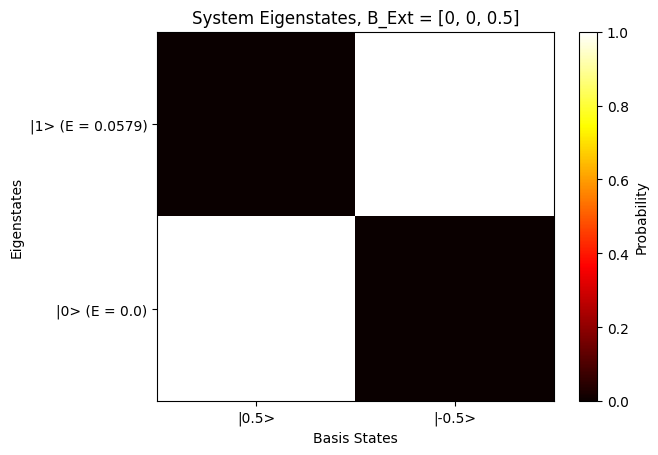

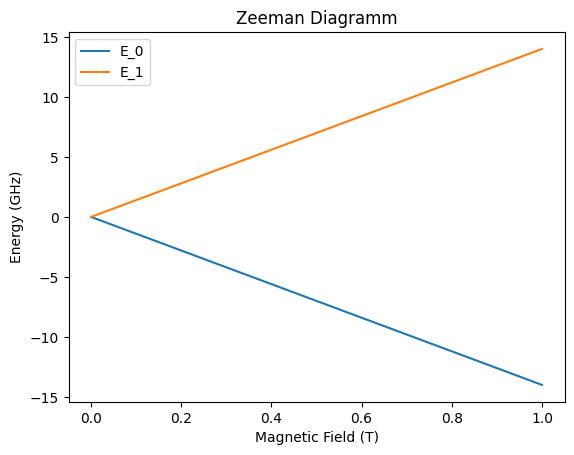

In [113]:
# Define the Spin System
spinsys=SpinSys([0.5])

# Add the Spin Hamiltonian parameters
spinsys.B=[0,0,0.5] #Add a magnetic field in Tesla
spinsys.BTip=[1e-7,0,0] # Add a tipfield for driving
spinsys.T=1 

vis.plotEigenMatrix(spinsys)
vis.plotZeemanDiagramm(spinsys)

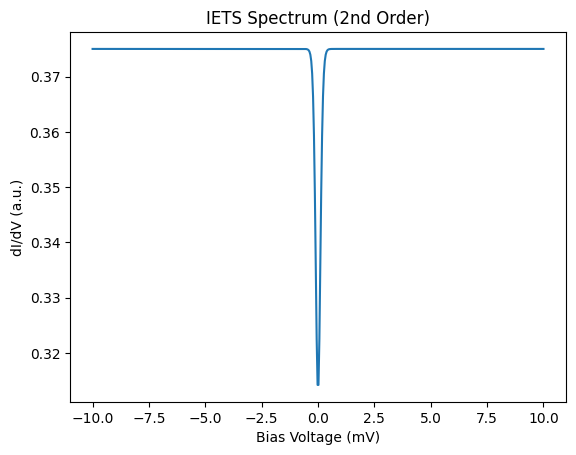

In [114]:
# dIdV Calculation
spinsys.T=0.5
spinsys.ReadoutSpin=0 # Set the readout spin
spinsys.TipPolarization=[0,0,0.0]
spinsys.B=[0,0,5] # Magnetic field in Tesla
vis.plotIETS(spinsys, Vrange=[-10,10], N=500, norm=False, order='2nd')

Precision threshold: 1e-06
Initial state index: 0
[[ 1.71056941e-49+0.j -6.25000000e-03+0.j]
 [-6.25000000e-03+0.j -6.25000000e-03+0.j]]
[[ 1.71056941e-49+0.j -6.25000000e-03+0.j]
 [-6.25000000e-03+0.j -6.25000000e-03+0.j]]
[[ 0.     +0.j -0.00625+0.j]
 [-0.00625+0.j -0.00625+0.j]]
[[ 0.     +0.j -0.00625+0.j]
 [-0.00625+0.j -0.00625+0.j]]
Dimension of eigVectors: 2
1
Precision threshold: 1e-06
Initial state index: 0
[[ 1.71056941e-49+0.j -6.25000000e-03+0.j]
 [-6.25000000e-03+0.j -6.25000000e-03+0.j]]
[[ 1.71056941e-49+0.j -6.25000000e-03+0.j]
 [-6.25000000e-03+0.j -6.25000000e-03+0.j]]
[[ 0.     +0.j -0.00625+0.j]
 [-0.00625+0.j -0.00625+0.j]]
[[ 0.     +0.j -0.00625+0.j]
 [-0.00625+0.j -0.00625+0.j]]
Dimension of eigVectors: 2
(100,) (100,)
Precision threshold: 1e-06
Initial state index: 1
[[-6.25000000e-03+0.j -6.25000000e-03+0.j]
 [-6.25000000e-03+0.j -1.71056941e-49+0.j]]
[[-6.25000000e-03+0.j -6.25000000e-03+0.j]
 [-6.25000000e-03+0.j -1.71056941e-49+0.j]]
[[-0.00625+0.j -0.0062

ValueError: not enough values to unpack (expected 3, got 2)

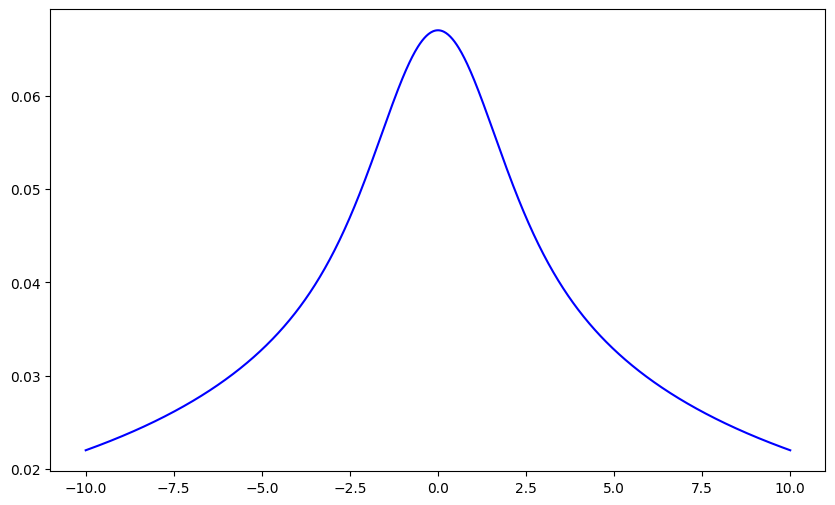

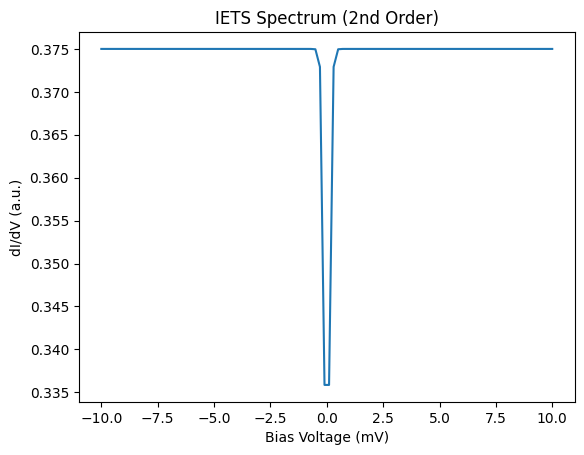

In [ ]:
spinsys.J=-0.1  # Set the Kondo coupling strength
spinsys.B=[0,0,1]
spinsys.BTip=[0,0,0] # Add a tipfield for driving
spinsys.T=0.5  # Set the temperature

V_array = np.linspace(-10, 10, 1000)  # Define the voltage range for the calculation
[V_array, y, yr]  = dIdV3.spec3(spinsys, 0, V_array)  # Calculate the energy levels
plt.figure(figsize=(10, 6))
plt.plot(V_array, y, label='dI/dV', color='blue')

dIdV.calcIETS_2nd(spinsys, V_array, norm=False)  # Calculate the second order IETS:
vis.plotIETS(spinsys, Vrange=[-10, 10], norm=False, order='2nd')
dIdV3.calcIETS_3rd(spinsys, Vrange=[-10, 10], N=100, norm=False)
vis.plotIETS(spinsys, Vrange=[-10, 10], order='1rd')